# MindCheck – Depression & Anxiety Screener

In [1]:
import os

In [2]:
import numpy as np

In [3]:
import pandas as pd

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [7]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [8]:
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

In [9]:
DATA_DIR = "data"
files = ["phq9", "gad7", "isi", "pss", "demographic"]

In [10]:
for f in files:
    path = os.path.join(DATA_DIR, f + ".csv")
    print(f, "found:", os.path.exists(path))

phq9 found: True
gad7 found: True
isi found: True
pss found: True
demographic found: True


In [11]:
raw = {}
for f in files:
    raw[f] = pd.read_csv(os.path.join(DATA_DIR, f + ".csv"))

In [12]:
for f in files:
    print(f, "shape:", raw[f].shape)

phq9 shape: (24292, 20)
gad7 shape: (24292, 16)
isi shape: (24292, 16)
pss shape: (24292, 30)
demographic shape: (24292, 6)


In [13]:
print(raw["phq9"].head(3))

   export_id  score  question1  time1  question2  time2  question3  time3  \
0      61793      0          0   2.47          0   1.23          0   1.12   
1      61809      0          0   8.22          0   7.08          0   1.24   
2      61737      0          0   1.88          0   1.65          0   1.00   

   question4  time4  question5  time5  question6  time6  question7  time7  \
0          0   1.73          0   4.74          0   1.32          0   0.16   
1          0   1.08          0   1.77          0   1.26          0   1.05   
2          0   1.18          0   0.81          0   1.29          0   4.17   

   question8  time8  question9  time9  
0          0  12.99          0   4.00  
1          0   2.07          0   3.76  
2          0   1.29          0   4.58  


In [14]:
print(raw["pss"].head(3))

   export_id  score  question1  time1  question2  time2  question3  time3  \
0      61793      2          1   2.59          1   2.12          1   2.83   
1      61809     21          2   5.10          1   3.97          1   0.97   
2      61737      4          1   7.44          1   2.74          1   1.76   

   question4  time4  question5  time5  question6  time6  question7  time7  \
0          1   0.72          1   3.94          1   2.98          1   9.41   
1          5   0.77          5   0.78          2  11.83          4   4.47   
2          1   3.82          1   2.83          1   2.25          1   1.43   

   question8  time8  question9  time9  question10  time10  question11  time11  \
0          1   4.68          1   2.37           1    3.88           1    2.80   
1          2   3.64          2   8.50           5    2.78           1    1.91   
2          1   8.20          1   4.11           1    2.73           1    5.56   

   question12  time12  question13  time13  question14  ti

In [15]:
print(raw["demographic"].head(3))

   export_id  gender   age                edu         smoke  \
0      61793  female  19.0  bachelor's degree  never smokes   
1      61809  female  18.0  bachelor's degree  never smokes   
2      61737    male  40.0    master's degree  never smokes   

                                         drink  
0                                 never drinks  
1                                 never drinks  
2  drinks occasionally (less than once a week)  


In [16]:
for f in files:
    print(f, "missing values:", int(raw[f].isnull().sum().sum()))

phq9 missing values: 0
gad7 missing values: 0
isi missing values: 0
pss missing values: 0
demographic missing values: 0


In [17]:
for f in files:
    print(f, "duplicate IDs:", raw[f]["export_id"].duplicated().sum())

phq9 duplicate IDs: 0
gad7 duplicate IDs: 0
isi duplicate IDs: 0
pss duplicate IDs: 0
demographic duplicate IDs: 0


In [18]:
for f in files:
    print(f, "duplicate rows:", raw[f].duplicated().sum())

phq9 duplicate rows: 0
gad7 duplicate rows: 0
isi duplicate rows: 0
pss duplicate rows: 0
demographic duplicate rows: 0


In [19]:
id_sets = [set(raw[f]["export_id"]) for f in files]
common_ids = set.intersection(*id_sets)
print("IDs in every file:", len(common_ids))
print("IDs in phq9:", len(id_sets[0]))

IDs in every file: 24292
IDs in phq9: 24292


In [20]:
for f in ["phq9", "gad7", "isi", "pss"]:
    q_cols = [c for c in raw[f].columns if c.startswith("question")]
    print(f, "| questions:", len(q_cols), "| min:", raw[f][q_cols].min().min(), "| max:", raw[f][q_cols].max().max())

phq9 | questions: 9 | min: 0 | max: 3
gad7 | questions: 7 | min: 0 | max: 3
isi | questions: 7 | min: 0 | max: 4
pss | questions: 14 | min: 1 | max: 5


In [21]:
for f in ["phq9", "gad7", "isi", "pss"]:
    q_cols = [c for c in raw[f].columns if c.startswith("question")]
    match = (raw[f][q_cols].sum(axis=1) == raw[f]["score"]).mean()
    print(f, "score equals sum of answers:", round(match * 100, 1), "%")

phq9 score equals sum of answers: 100.0 %
gad7 score equals sum of answers: 100.0 %
isi score equals sum of answers: 100.0 %
pss score equals sum of answers: 0.0 %


In [22]:
print(raw["phq9"]["score"].describe().round(2))

count    24292.00
mean         3.27
std          3.71
min          0.00
25%          0.00
50%          2.00
75%          5.00
max         27.00
Name: score, dtype: float64


In [23]:
print(raw["gad7"]["score"].describe().round(2))

count    24292.00
mean         1.91
std          2.92
min          0.00
25%          0.00
50%          0.00
75%          3.00
max         21.00
Name: score, dtype: float64


In [24]:
demo_raw = raw["demographic"]
print(demo_raw["age"].describe().round(2))

count    24292.00
mean        20.66
std          2.41
min          1.00
25%         19.00
50%         20.00
75%         22.00
max         99.00
Name: age, dtype: float64


In [25]:
for col in ["gender", "edu", "smoke", "drink"]:
    print("\n", col)
    print(demo_raw[col].value_counts())


 gender
gender
female    15545
male       8747
Name: count, dtype: int64

 edu
edu
bachelor's degree    22290
associate degree      1285
master's degree        675
doctorate degree        42
Name: count, dtype: int64

 smoke
smoke
never smokes                                                              22513
occasional smoker (cumulative smoking <10 packs)                           1044
current smoker (cumulative smoking >10 packs)                               542
former smoker (cumulative smoking >10 packs), but not in the past year      193
Name: count, dtype: int64

 drink
drink
never drinks                                                           16404
drinks occasionally (less than once a week)                             7359
drank in the past (more than once a week), but not in the past year      284
current regular drinker (more than once a week)                          245
Name: count, dtype: int64


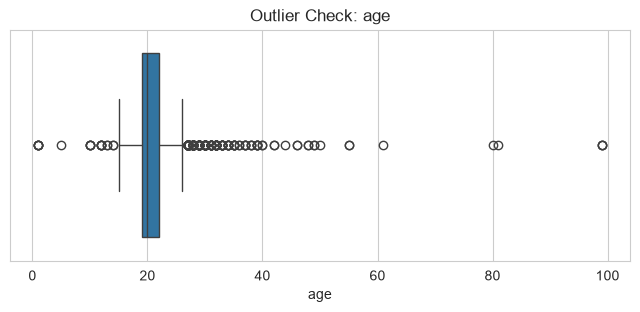

In [26]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=demo_raw["age"])
plt.title("Outlier Check: age")
plt.show()

In [27]:
q1 = demo_raw["age"].quantile(0.25)
q3 = demo_raw["age"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Flagged Values:", ((demo_raw["age"] < lower) | (demo_raw["age"] > upper)).sum())

Lower Bound: 14.5
Upper Bound: 26.5
Flagged Values: 299


IQR se normal students ki age 14.5-26.5 aati hai, par college students 40 tak ho sakte hain. Isliye 16-40 rakhenge.

In [28]:
print("Age < 16:", (demo_raw["age"] < 16).sum())
print("Age > 40:", (demo_raw["age"] > 40).sum())

Age < 16: 22
Age > 40: 18


In [29]:
time_cols = [c for c in raw["phq9"].columns if c.startswith("time")]
all_times = raw["phq9"][time_cols].stack()
print(all_times.describe().round(2))

count    218628.00
mean          4.73
std          25.73
min           0.01
25%           1.69
50%           3.00
75%           5.07
max        5370.34
dtype: float64


In [30]:
print("Answers taking more than 300 sec:", (all_times > 300).sum())

Answers taking more than 300 sec: 90


In [31]:
def prepare(name):
    d = raw[name].copy()
    d = d.rename(columns={"export_id": "id"})
    q_cols = [c for c in d.columns if c.startswith("question")]
    t_cols = [c for c in d.columns if c.startswith("time")]
    out = pd.DataFrame({"id": d["id"], name + "_score": d["score"]})
    for c in q_cols:
        out[name + "_" + c.replace("question", "q")] = d[c]
    out[name + "_time"] = d[t_cols].sum(axis=1)
    return out

In [32]:
phq = prepare("phq9")
gad = prepare("gad7")
isi = prepare("isi")
pss = prepare("pss")

In [33]:
print(phq.shape, gad.shape, isi.shape, pss.shape)
print(list(phq.columns))

(24292, 12) (24292, 10) (24292, 10) (24292, 17)
['id', 'phq9_score', 'phq9_q1', 'phq9_q2', 'phq9_q3', 'phq9_q4', 'phq9_q5', 'phq9_q6', 'phq9_q7', 'phq9_q8', 'phq9_q9', 'phq9_time']


In [34]:
demo = raw["demographic"].rename(columns={"export_id": "id"}).copy()
bad_age = (demo["age"] < 16) | (demo["age"] > 40)
print("Rows to remove:", bad_age.sum())
print("Percent:", round(bad_age.mean() * 100, 3), "%")

Rows to remove: 40
Percent: 0.165 %


In [35]:
demo = demo[~bad_age].copy()
demo["age"] = demo["age"].astype(int)
print("Demographic shape:", demo.shape)
print("Minimum age:", demo["age"].min())
print("Maximum age:", demo["age"].max())

Demographic shape: (24252, 6)
Minimum age: 16
Maximum age: 40


In [36]:
for col in ["edu", "smoke", "drink"]:
    print(col, demo[col].unique())

edu <StringArray>
['bachelor's degree', 'master's degree', 'doctorate degree',
 'associate degree']
Length: 4, dtype: str
smoke <StringArray>
[                                                          'never smokes',
                          'current smoker (cumulative smoking >10 packs)',
 'former smoker (cumulative smoking >10 packs), but not in the past year',
                       'occasional smoker (cumulative smoking <10 packs)']
Length: 4, dtype: str
drink <StringArray>
[                                                       'never drinks',
                         'drinks occasionally (less than once a week)',
 'drank in the past (more than once a week), but not in the past year',
                     'current regular drinker (more than once a week)']
Length: 4, dtype: str


In [37]:
demo["edu"] = demo["edu"].str.split().str[0].str.replace("'s", "", regex=False)
demo["smoke"] = demo["smoke"].str.split().str[0]

In [38]:
def short_drink(x):
    if x.startswith("never"):
        return "never"
    if x.startswith("drinks occasionally"):
        return "occasional"
    if x.startswith("drank in the past"):
        return "past"
    return "regular"

demo["drink"] = demo["drink"].apply(short_drink)

In [39]:
for col in ["edu", "smoke", "drink"]:
    print("\n", col)
    print(demo[col].value_counts())


 edu
edu
bachelor     22269
associate     1278
master         672
doctorate       33
Name: count, dtype: int64

 smoke
smoke
never         22481
occasional     1041
current         541
former          189
Name: count, dtype: int64

 drink
drink
never         16377
occasional     7351
past            283
regular         241
Name: count, dtype: int64


In [40]:
print("Missing after cleaning:", int(demo.isnull().sum().sum()))

Missing after cleaning: 0


In [41]:
df = phq.merge(gad, on="id").merge(isi, on="id").merge(pss, on="id").merge(demo, on="id")
print("Merged shape:", df.shape)

Merged shape: (24252, 51)


In [42]:
print("Duplicate IDs:", df["id"].duplicated().sum())
print("Missing values:", int(df.isnull().sum().sum()))

Duplicate IDs: 0
Missing values: 0


In [43]:
print("Rows match expected:", len(df) == len(raw["phq9"]) - bad_age.sum())

Rows match expected: True


In [44]:
fast = df["phq9_time"] < 2
print("Too fast (< 2 sec total):", fast.sum())

Too fast (< 2 sec total): 0


In [45]:
print(df.head(3))

      id  phq9_score  phq9_q1  phq9_q2  phq9_q3  phq9_q4  phq9_q5  phq9_q6  \
0  61793           0        0        0        0        0        0        0   
1  61809           0        0        0        0        0        0        0   
2  61737           0        0        0        0        0        0        0   

   phq9_q7  phq9_q8  phq9_q9  phq9_time  gad7_score  gad7_q1  gad7_q2  \
0        0        0        0      29.76           0        0        0   
1        0        0        0      27.53           0        0        0   
2        0        0        0      17.85           0        0        0   

   gad7_q3  gad7_q4  gad7_q5  gad7_q6  gad7_q7  gad7_time  isi_score  isi_q1  \
0        0        0        0        0        0      16.85          0       0   
1        0        0        0        0        0      17.30          0       0   
2        0        0        0        0        0      23.66          0       0   

   isi_q2  isi_q3  ...  isi_q5  isi_q6  isi_q7  isi_time  pss_score  pss_

In [46]:
phq_q = [c for c in df.columns if c.startswith("phq9_q")]
gad_q = [c for c in df.columns if c.startswith("gad7_q")]
print("PHQ-9 questions:", len(phq_q))
print("GAD-7 questions:", len(gad_q))

PHQ-9 questions: 9
GAD-7 questions: 7


In [47]:
print("PHQ-9 score matches:", (df[phq_q].sum(axis=1) == df["phq9_score"]).all())
print("GAD-7 score matches:", (df[gad_q].sum(axis=1) == df["gad7_score"]).all())

PHQ-9 score matches: True
GAD-7 score matches: True


In [48]:
df["phq9_level"] = pd.cut(
    df["phq9_score"],
    bins=[-1, 4, 9, 14, 19, 27],
    labels=["Minimal", "Mild", "Moderate", "Mod. severe", "Severe"]
)

In [49]:
df["gad7_level"] = pd.cut(
    df["gad7_score"],
    bins=[-1, 4, 9, 14, 21],
    labels=["Minimal", "Mild", "Moderate", "Severe"]
)

In [50]:
df["isi_level"] = pd.cut(
    df["isi_score"],
    bins=[-1, 7, 14, 21, 28],
    labels=["None", "Subthreshold", "Moderate", "Severe"]
)

In [51]:
print(df["phq9_level"].value_counts().sort_index())
print(df["gad7_level"].value_counts().sort_index())
print(df["isi_level"].value_counts().sort_index())

phq9_level
Minimal        16861
Mild            6084
Moderate         953
Mod. severe      260
Severe            94
Name: count, dtype: int64
gad7_level
Minimal     20146
Mild         3566
Moderate      383
Severe        157
Name: count, dtype: int64
isi_level
None            22058
Subthreshold     1916
Moderate          242
Severe             36
Name: count, dtype: int64


In [52]:
print(df[["phq9_level", "gad7_level", "isi_level"]].isnull().sum())

phq9_level    0
gad7_level    0
isi_level     0
dtype: int64


In [53]:
df["phq_pos"] = (df["phq9_score"] >= 10).astype(int)
df["gad_pos"] = (df["gad7_score"] >= 10).astype(int)

In [54]:
print("PHQ-9 positive %:", round(df["phq_pos"].mean() * 100, 2))
print("GAD-7 positive %:", round(df["gad_pos"].mean() * 100, 2))

PHQ-9 positive %: 5.39
GAD-7 positive %: 2.23


Positive cases kam hain (imbalanced data). ML mein iska dhyan rakhna padega.

PHQ-9 ka Q9 self-harm thoughts ke bare mein hai. Dekhte hain kitno ne 0 se zyada jawab diya.

In [55]:
df["q9_flag"] = (df["phq9_q9"] > 0).astype(int)
print(df["q9_flag"].value_counts())
print("Percent:", round(df["q9_flag"].mean() * 100, 2), "%")

q9_flag
0    22419
1     1833
Name: count, dtype: int64
Percent: 7.56 %


In [56]:
print("Avg PHQ-9 with Q9 flag:", round(df.loc[df["q9_flag"] == 1, "phq9_score"].mean(), 2))
print("Avg PHQ-9 without Q9 flag:", round(df.loc[df["q9_flag"] == 0, "phq9_score"].mean(), 2))

Avg PHQ-9 with Q9 flag: 9.74
Avg PHQ-9 without Q9 flag: 2.73


Real app mein Q9 > 0 par alag safety flow chalega, ML par depend nahi karega.

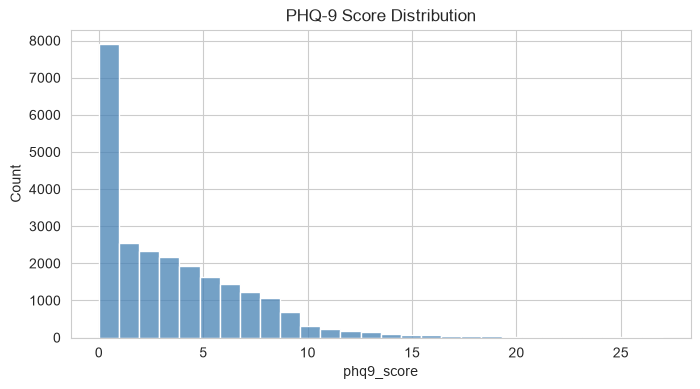

In [57]:
plt.figure(figsize=(8, 4))
sns.histplot(df["phq9_score"], bins=28, color="steelblue")
plt.title("PHQ-9 Score Distribution")
plt.show()

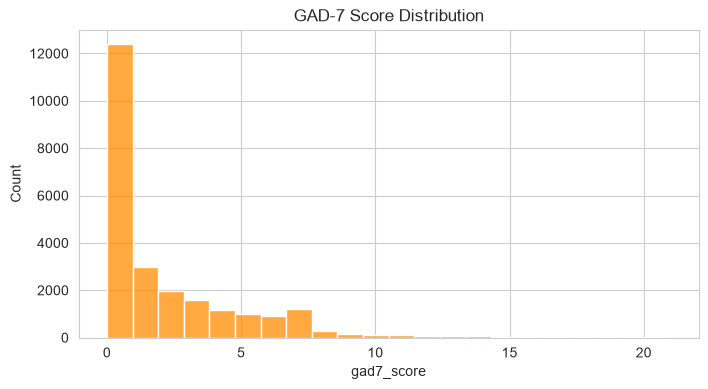

In [58]:
plt.figure(figsize=(8, 4))
sns.histplot(df["gad7_score"], bins=22, color="darkorange")
plt.title("GAD-7 Score Distribution")
plt.show()

Dono right-skewed hain. Zyada students ka score kam hai.

In [59]:
phq_pct = df["phq9_level"].value_counts(normalize=True).sort_index() * 100
gad_pct = df["gad7_level"].value_counts(normalize=True).sort_index() * 100
print(phq_pct.round(2))
print(gad_pct.round(2))

phq9_level
Minimal        69.52
Mild           25.09
Moderate        3.93
Mod. severe     1.07
Severe          0.39
Name: proportion, dtype: float64
gad7_level
Minimal     83.07
Mild        14.70
Moderate     1.58
Severe       0.65
Name: proportion, dtype: float64


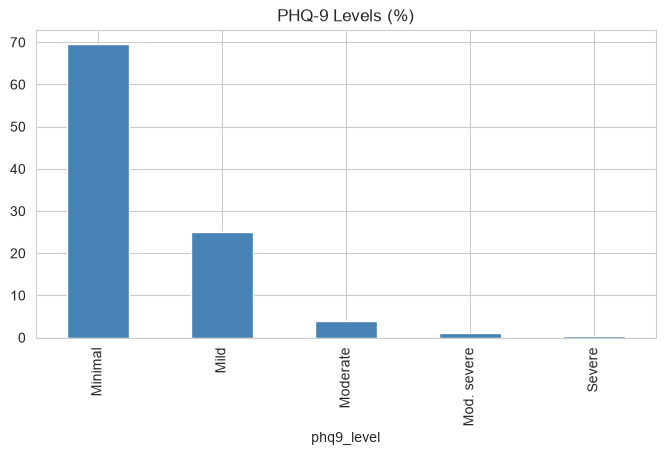

In [60]:
plt.figure(figsize=(8, 4))
phq_pct.plot(kind="bar", color="steelblue")
plt.title("PHQ-9 Levels (%)")
plt.show()

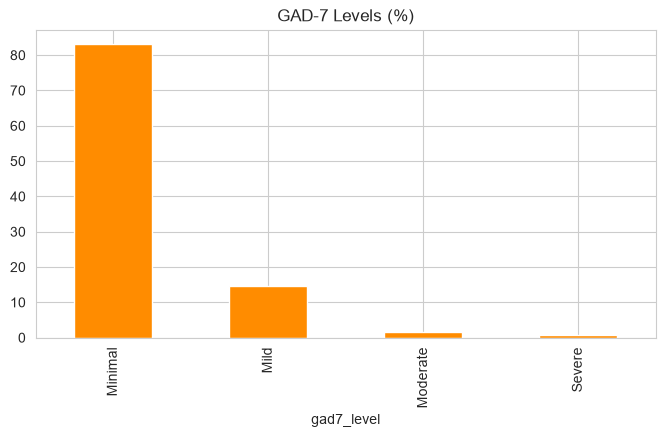

In [61]:
plt.figure(figsize=(8, 4))
gad_pct.plot(kind="bar", color="darkorange")
plt.title("GAD-7 Levels (%)")
plt.show()

Depression aur anxiety kitne related hain?

In [62]:
print("PHQ-9 vs GAD-7 correlation:", round(df["phq9_score"].corr(df["gad7_score"]), 3))

PHQ-9 vs GAD-7 correlation: 0.766


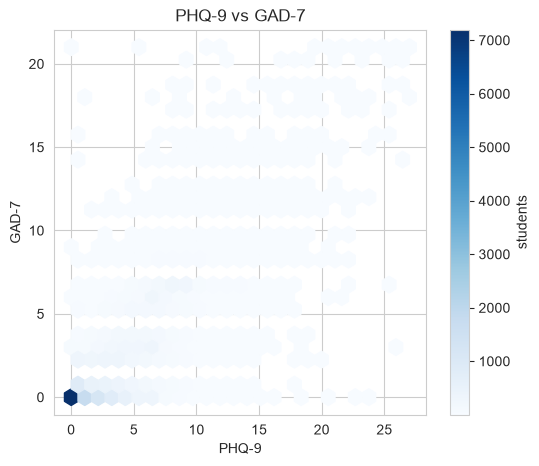

In [63]:
plt.figure(figsize=(6, 5))
plt.hexbin(df["phq9_score"], df["gad7_score"], gridsize=25, cmap="Blues", mincnt=1)
plt.colorbar(label="students")
plt.xlabel("PHQ-9")
plt.ylabel("GAD-7")
plt.title("PHQ-9 vs GAD-7")
plt.show()

Dono mein positive kitne students hain?

In [64]:
print(pd.crosstab(df["phq_pos"], df["gad_pos"], margins=True))

gad_pos      0    1    All
phq_pos                   
0        22814  131  22945
1          898  409   1307
All      23712  540  24252


In [65]:
print((pd.crosstab(df["phq_pos"], df["gad_pos"], normalize=True) * 100).round(2))

gad_pos      0     1
phq_pos             
0        94.07  0.54
1         3.70  1.69


Sleep (ISI) aur stress (PSS) ka link.

In [66]:
score_cols = ["phq9_score", "gad7_score", "isi_score", "pss_score"]
corr = df[score_cols].corr().round(2)
print(corr)

            phq9_score  gad7_score  isi_score  pss_score
phq9_score        1.00        0.77       0.65       0.50
gad7_score        0.77        1.00       0.60       0.49
isi_score         0.65        0.60       1.00       0.40
pss_score         0.50        0.49       0.40       1.00


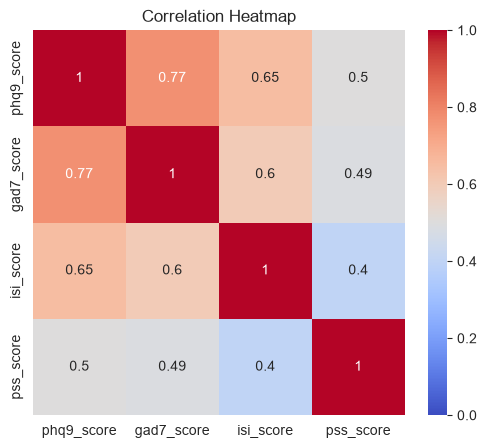

In [67]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

In [68]:
print(df.groupby("isi_level", observed=True)[["phq9_score", "gad7_score"]].mean().round(2))

              phq9_score  gad7_score
isi_level                           
None                2.71        1.50
Subthreshold        8.20        5.56
Moderate           12.25        8.71
Severe             16.33       13.25


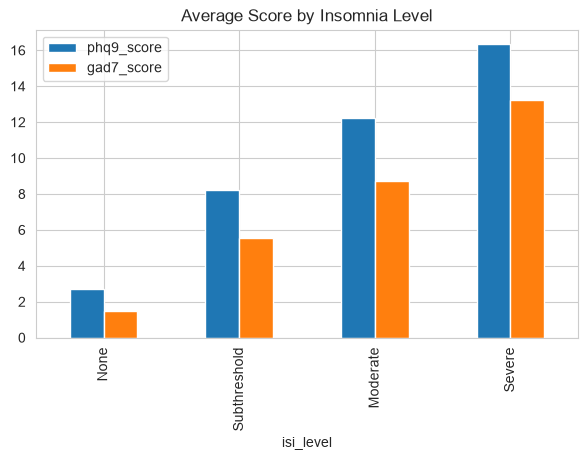

In [69]:
df.groupby("isi_level", observed=True)[["phq9_score", "gad7_score"]].mean().plot(kind="bar", figsize=(7, 4))
plt.title("Average Score by Insomnia Level")
plt.show()

Ab demographics. Pehle gender.

In [70]:
print(df.groupby("gender")[["phq9_score", "gad7_score", "isi_score", "pss_score"]].mean().round(2))

        phq9_score  gad7_score  isi_score  pss_score
gender                                              
female        3.34        1.99       2.77      19.81
male          3.12        1.76       2.78      20.29


In [71]:
print((df.groupby("gender")[["phq_pos", "gad_pos"]].mean() * 100).round(2))

        phq_pos  gad_pos
gender                  
female     5.17     2.20
male       5.77     2.28


Education, smoking, drinking. Pehle group size dekho, chhote groups ka average bharosemand nahi hota.

In [72]:
for col in ["edu", "smoke", "drink"]:
    print("\n", col)
    print(df.groupby(col)[["phq9_score", "gad7_score"]].agg(["mean", "count"]).round(2))


 edu
          phq9_score        gad7_score       
                mean  count       mean  count
edu                                          
associate       3.42   1278       2.02   1278
bachelor        3.27  22269       1.91  22269
doctorate       3.94     33       2.70     33
master          2.68    672       1.84    672

 smoke
           phq9_score        gad7_score       
                 mean  count       mean  count
smoke                                         
current          4.89    541       2.93    541
former           4.48    189       2.70    189
never            3.17  22481       1.85  22481
occasional       4.11   1041       2.46   1041

 drink
           phq9_score        gad7_score       
                 mean  count       mean  count
drink                                         
never            2.88  16377       1.69  16377
occasional       3.97   7351       2.31   7351
past             4.91    283       2.89    283
regular          5.88    241       3.37    24

Doctorate jaise chhote groups ko interpret karte waqt dhyan rakhna.

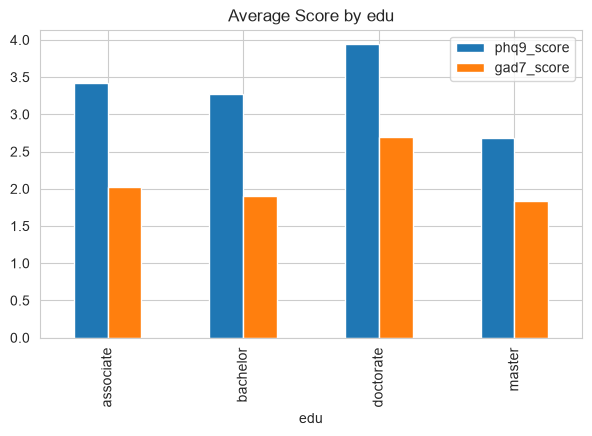

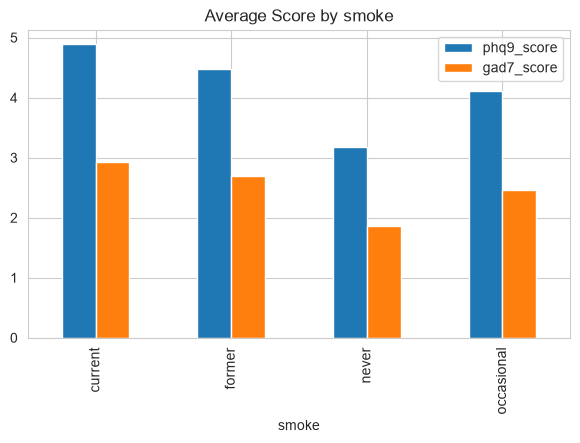

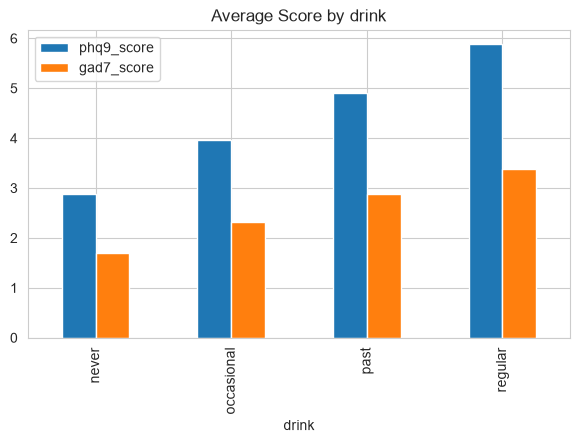

In [73]:
for col in ["edu", "smoke", "drink"]:
    df.groupby(col)[["phq9_score", "gad7_score"]].mean().plot(kind="bar", figsize=(7, 4))
    plt.title("Average Score by " + col)
    plt.show()

Age ke hisaab se score (17-28 age, kyunki baaki ke students bahut kam hain).

In [74]:
age_view = df[df["age"].between(17, 28)]
print(age_view["age"].value_counts().sort_index().head(3))

age
17     183
18    2609
19    4641
Name: count, dtype: int64


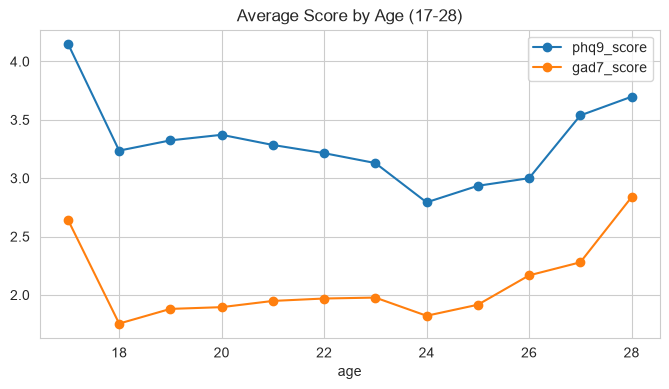

In [75]:
age_view.groupby("age")[["phq9_score", "gad7_score"]].mean().plot(figsize=(8, 4), marker="o")
plt.title("Average Score by Age (17-28)")
plt.show()

PHQ-9 ke answers se PHQ-9 predict karna bekaar hai (ye sirf addition hai). Isliye sleep, stress aur demographics se predict karenge ki score 10+ hoga ya nahi.

In [76]:
num_cols = ["isi_score", "pss_score", "age"]
cat_cols = ["gender", "edu", "smoke", "drink"]
X = df[num_cols + cat_cols]
print("Features shape:", X.shape)

Features shape: (24252, 7)


In [77]:
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print("PHQ-9 and GAD-7 answers/scores are NOT in features (to avoid leakage)")

Numerical columns: ['isi_score', 'pss_score', 'age']
Categorical columns: ['gender', 'edu', 'smoke', 'drink']
PHQ-9 and GAD-7 answers/scores are NOT in features (to avoid leakage)


Baseline: agar model hamesha "negative" bole to accuracy kitni aayegi?

In [78]:
for target in ["phq_pos", "gad_pos"]:
    print(target, "always-negative accuracy:", round((1 - df[target].mean()) * 100, 2), "%")

phq_pos always-negative accuracy: 94.61 %
gad_pos always-negative accuracy: 97.77 %


In [79]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    df["phq_pos"],
    test_size=0.2,
    random_state=42,
    stratify=df["phq_pos"]
)

In [80]:
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Train positive %:", round(y_train.mean() * 100, 2))
print("Test positive %:", round(y_test.mean() * 100, 2))

Training rows: 19401
Testing rows: 4851
Train positive %: 5.39
Test positive %: 5.38


In [81]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

4 models try karte hain. `class_weight="balanced"` isliye ki positive cases kam hain.

In [82]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

Dono targets (PHQ-9 aur GAD-7) ke liye sab models chalate hain.

In [83]:
results = []
fitted = {}
for target in ["phq_pos", "gad_pos"]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, df[target], test_size=0.2, random_state=42, stratify=df[target]
    )
    for name, model in models.items():
        pipeline = Pipeline([
            ("preprocessing", preprocessor),
            ("model", model)
        ])
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        y_proba = pipeline.predict_proba(X_test)[:, 1]
        fitted[(target, name)] = (pipeline, y_test, y_pred)
        results.append({
            "Target": target,
            "Model": name,
            "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
            "Precision": round(precision_score(y_test, y_pred, zero_division=0), 3),
            "Recall": round(recall_score(y_test, y_pred, zero_division=0), 3),
            "F1": round(f1_score(y_test, y_pred, zero_division=0), 3),
            "ROC-AUC": round(roc_auc_score(y_test, y_proba), 3)
        })

In [84]:
results_df = pd.DataFrame(results)
print("Final Model Comparison:")
print(results_df.to_string(index=False))

Final Model Comparison:
 Target               Model  Accuracy (%)  Precision  Recall    F1  ROC-AUC
phq_pos                 KNN         95.09      0.585   0.303 0.399    0.792
phq_pos       Decision Tree         86.33      0.258   0.820 0.392    0.916
phq_pos       Random Forest         86.93      0.268   0.824 0.404    0.921
phq_pos Logistic Regression         87.22      0.278   0.862 0.421    0.932
gad_pos                 KNN         97.88      0.558   0.222 0.318    0.793
gad_pos       Decision Tree         89.86      0.162   0.852 0.272    0.929
gad_pos       Random Forest         91.94      0.193   0.824 0.313    0.938
gad_pos Logistic Regression         88.81      0.153   0.889 0.261    0.945


Best model ROC-AUC se chunenge. Accuracy imbalanced data mein misleading hai, aur KNN ka recall bahut kam hai (positive cases miss karta hai).

In [85]:
best_models = {}
for target in ["phq_pos", "gad_pos"]:
    sub = results_df[results_df["Target"] == target].sort_values(by="ROC-AUC", ascending=False)
    best_models[target] = sub.iloc[0]["Model"]
    print(target, "-> Best Model:", best_models[target], "| ROC-AUC:", sub.iloc[0]["ROC-AUC"])

phq_pos -> Best Model: Logistic Regression | ROC-AUC: 0.932
gad_pos -> Best Model: Logistic Regression | ROC-AUC: 0.945


Best models ka classification report.

In [86]:
for target in ["phq_pos", "gad_pos"]:
    pipeline, y_test, y_pred = fitted[(target, best_models[target])]
    print("\n", "=" * 50)
    print("Target:", target, "| Model:", best_models[target])
    print("=" * 50)
    print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], zero_division=0))


Target: phq_pos | Model: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.99      0.87      0.93      4590
    Positive       0.28      0.86      0.42       261

    accuracy                           0.87      4851
   macro avg       0.63      0.87      0.67      4851
weighted avg       0.95      0.87      0.90      4851


Target: gad_pos | Model: Logistic Regression
              precision    recall  f1-score   support

    Negative       1.00      0.89      0.94      4743
    Positive       0.15      0.89      0.26       108

    accuracy                           0.89      4851
   macro avg       0.58      0.89      0.60      4851
weighted avg       0.98      0.89      0.92      4851



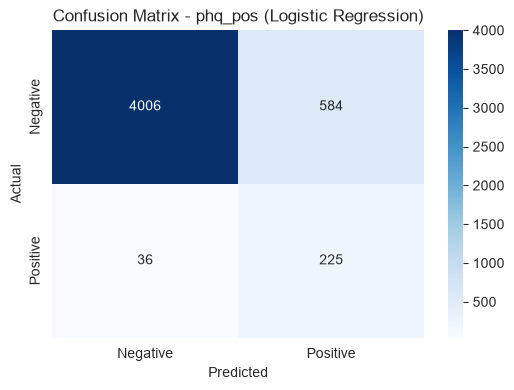

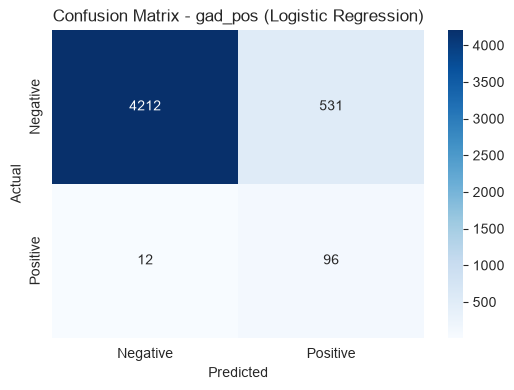

In [87]:
for target in ["phq_pos", "gad_pos"]:
    pipeline, y_test, y_pred = fitted[(target, best_models[target])]
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Negative", "Positive"],
                yticklabels=["Negative", "Positive"])
    plt.title("Confusion Matrix - " + target + " (" + best_models[target] + ")")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

Logistic Regression se dekhte hain kaunsa feature sabse zyada matter karta hai.

In [88]:
phq_lr = fitted[("phq_pos", "Logistic Regression")][0]
feature_names = phq_lr.named_steps["preprocessing"].get_feature_names_out()
coef = pd.Series(phq_lr.named_steps["model"].coef_[0], index=feature_names).sort_values()
print(coef.round(3))

cat__edu_associate      -0.663
cat__edu_bachelor       -0.655
cat__drink_never        -0.579
cat__gender_male        -0.530
cat__smoke_former       -0.507
cat__drink_occasional   -0.470
cat__smoke_never        -0.448
cat__edu_master         -0.373
cat__drink_regular      -0.313
cat__gender_female      -0.298
cat__smoke_occasional   -0.219
num__age                 0.065
cat__smoke_current       0.345
cat__drink_past          0.533
cat__edu_doctorate       0.863
num__isi_score           0.884
num__pss_score           2.266
dtype: float64


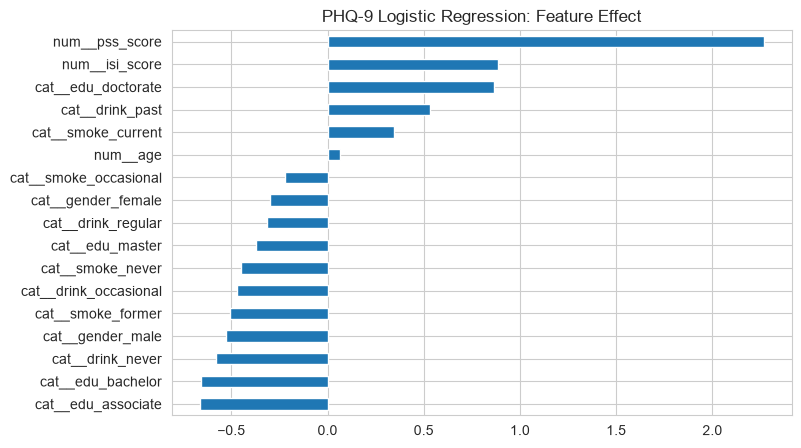

In [89]:
plt.figure(figsize=(8, 5))
coef.plot(kind="barh")
plt.title("PHQ-9 Logistic Regression: Feature Effect")
plt.show()

**Limitation:** Ye exploratory model hai, clinical prediction nahi. Data Chinese students ka hai, Indian users par validate karna zaroori hai.

---
# Model Improvement

Improvement 1: Cross-validation. Result ek lucky split par depend na kare, isliye 5 baar alag-alag test karte hain.

In [90]:
import joblib
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import precision_recall_curve

In [91]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [92]:
lr_pipe = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [93]:
for target in ["phq_pos", "gad_pos"]:
    scores = cross_val_score(lr_pipe, X, df[target], cv=cv, scoring="roc_auc")
    print(target, "| CV ROC-AUC:", scores.round(3), "| Mean:", round(scores.mean(), 3), "| Std:", round(scores.std(), 3))

phq_pos | CV ROC-AUC: [0.944 0.933 0.947 0.942 0.927] | Mean: 0.938 | Std: 0.007
gad_pos | CV ROC-AUC: [0.949 0.938 0.964 0.958 0.956] | Mean: 0.953 | Std: 0.009


Std bahut chhota hai, matlab result stable hai.

In [94]:
item_cols = [c for c in df.columns if c.startswith("isi_q") or c.startswith("pss_q")]
print("Item columns:", len(item_cols))
print(item_cols)

Item columns: 21
['isi_q1', 'isi_q2', 'isi_q3', 'isi_q4', 'isi_q5', 'isi_q6', 'isi_q7', 'pss_q1', 'pss_q2', 'pss_q3', 'pss_q4', 'pss_q5', 'pss_q6', 'pss_q7', 'pss_q8', 'pss_q9', 'pss_q10', 'pss_q11', 'pss_q12', 'pss_q13', 'pss_q14']


In [95]:
num_cols_item = num_cols + item_cols
X_item = df[num_cols_item + cat_cols]
print("Item-level features shape:", X_item.shape)

Item-level features shape: (24252, 28)


In [96]:
preprocessor_item = ColumnTransformer([
    ("num", StandardScaler(), num_cols_item),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

Totals aur item-level ko same split par compare karte hain.

In [97]:
compare_rows = []
for target in ["phq_pos", "gad_pos"]:
    for label, feats, prep in [("Totals only", X, preprocessor), ("Item-level", X_item, preprocessor_item)]:
        X_tr, X_te, y_tr, y_te = train_test_split(
            feats, df[target], test_size=0.2, random_state=42, stratify=df[target]
        )
        pipe = Pipeline([
            ("preprocessing", prep),
            ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
        ])
        pipe.fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        compare_rows.append({
            "Target": target,
            "Features": label,
            "ROC-AUC": round(roc_auc_score(y_te, proba), 3)
        })

In [98]:
print(pd.DataFrame(compare_rows).to_string(index=False))

 Target    Features  ROC-AUC
phq_pos Totals only    0.932
phq_pos  Item-level    0.943
gad_pos Totals only    0.945
gad_pos  Item-level    0.951


Item-level mein ROC-AUC thoda badhta hai, isliye final model mein item-level use karenge.

Improvement 3: Threshold tuning. Default cut-off 0.5 hota hai. Hum recall 80% rakhkar best cut-off chunenge.

In [99]:
TARGET_RECALL = 0.80
print("Target recall:", TARGET_RECALL)

Target recall: 0.8


In [100]:
split_data = {}
for target in ["phq_pos", "gad_pos"]:
    split_data[target] = train_test_split(
        X_item, df[target], test_size=0.2, random_state=42, stratify=df[target]
    )
print("Splits ready:", list(split_data.keys()))

Splits ready: ['phq_pos', 'gad_pos']


Threshold training data se chunenge (cross_val_predict). Test data se chunenge to test "dekh" liya jayega, aur result jhootha achha dikhega.

In [101]:
item_lr = Pipeline([
    ("preprocessing", preprocessor_item),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [102]:
thresholds = {}
for target in ["phq_pos", "gad_pos"]:
    X_tr, X_te, y_tr, y_te = split_data[target]
    cv_proba = cross_val_predict(item_lr, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_tr, cv_proba)
    ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
    best_idx = ok[-1]
    thresholds[target] = thr[best_idx]
    print(target, "| Chosen threshold:", round(thr[best_idx], 3),
          "| CV precision:", round(prec[best_idx], 3), "| CV recall:", round(rec[best_idx], 3))

phq_pos | Chosen threshold: 0.651 | CV precision: 0.375 | CV recall: 0.8
gad_pos | Chosen threshold: 0.833 | CV precision: 0.384 | CV recall: 0.801


Ab test data par default 0.5 aur tuned threshold ko compare karte hain.

In [103]:
thr_rows = []
test_proba = {}
for target in ["phq_pos", "gad_pos"]:
    X_tr, X_te, y_tr, y_te = split_data[target]
    pipe = Pipeline([
        ("preprocessing", preprocessor_item),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ])
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_te)[:, 1]
    test_proba[target] = proba
    for label, t in [("Default 0.5", 0.5), ("Tuned", thresholds[target])]:
        pred = (proba >= t).astype(int)
        thr_rows.append({
            "Target": target,
            "Threshold": label,
            "Cut-off": round(t, 3),
            "Precision": round(precision_score(y_te, pred, zero_division=0), 3),
            "Recall": round(recall_score(y_te, pred, zero_division=0), 3),
            "F1": round(f1_score(y_te, pred, zero_division=0), 3),
            "Flagged (%)": round(pred.mean() * 100, 2)
        })

In [104]:
print(pd.DataFrame(thr_rows).to_string(index=False))

 Target   Threshold  Cut-off  Precision  Recall    F1  Flagged (%)
phq_pos Default 0.5    0.500      0.284   0.862 0.428        16.31
phq_pos       Tuned    0.651      0.357   0.778 0.489        11.73
gad_pos Default 0.5    0.500      0.196   0.833 0.317         9.46
gad_pos       Tuned    0.833      0.366   0.759 0.494         4.62


Tuned threshold par precision badhti hai aur recall thodi kam hoti hai. `Flagged (%)` batata hai kitne students ko model alert dega.

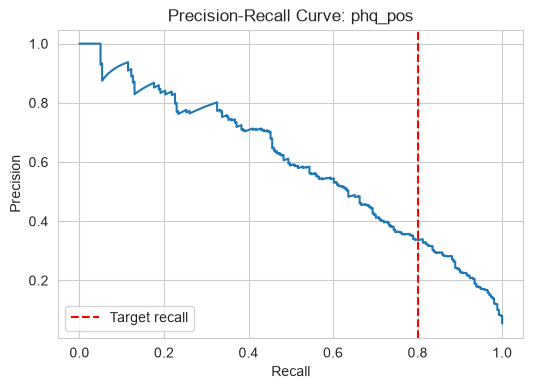

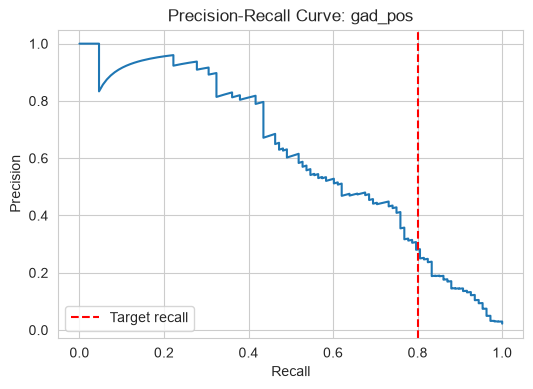

In [105]:
for target in ["phq_pos", "gad_pos"]:
    y_te = split_data[target][3]
    prec, rec, thr = precision_recall_curve(y_te, test_proba[target])
    plt.figure(figsize=(6, 4))
    plt.plot(rec, prec)
    plt.axvline(TARGET_RECALL, color="red", linestyle="--", label="Target recall")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve: " + target)
    plt.legend()
    plt.show()

Improvement 4: Feature importance.


 phq_pos - Top 10 features
edu_master      -0.606
drink_never     -0.575
edu_bachelor    -0.507
gender_female   -0.376
edu_associate   -0.374
pss_q13          0.319
pss_q7           0.373
pss_q3           0.395
pss_q2           0.468
edu_doctorate    0.914
dtype: float64


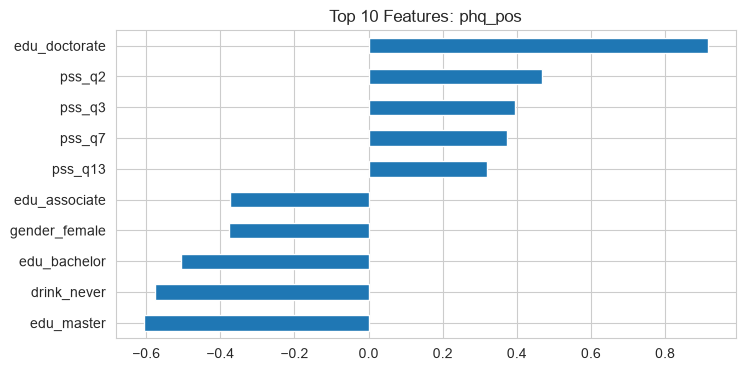


 gad_pos - Top 10 features
edu_bachelor    -1.007
edu_master      -0.918
smoke_never     -0.743
drink_regular   -0.742
edu_associate   -0.625
pss_q7           0.631
pss_q1           0.674
pss_q3           0.720
drink_past       0.770
edu_doctorate    1.763
dtype: float64


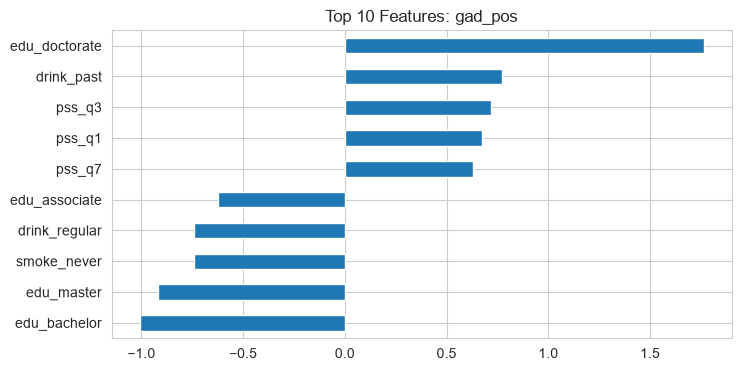

In [106]:
for target in ["phq_pos", "gad_pos"]:
    X_tr, X_te, y_tr, y_te = split_data[target]
    pipe = Pipeline([
        ("preprocessing", preprocessor_item),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ])
    pipe.fit(X_tr, y_tr)
    names = [n.split("__", 1)[1] for n in pipe.named_steps["preprocessing"].get_feature_names_out()]
    coef = pd.Series(pipe.named_steps["model"].coef_[0], index=names)
    top = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index).sort_values()
    print("\n", target, "- Top 10 features")
    print(top.round(3))
    plt.figure(figsize=(8, 4))
    top.plot(kind="barh")
    plt.title("Top 10 Features: " + target)
    plt.show()

Sleep (ISI) aur stress (PSS) ke features upar aate hain. Ye hamari EDA se match karta hai.

In [107]:
os.makedirs("output", exist_ok=True)
df.to_csv("output/zenodo_cleaned_scored.csv", index=False)
print("Cleaned data saved:", df.shape)

Cleaned data saved: (24252, 57)


In [108]:
final_models = {}
for target in ["phq_pos", "gad_pos"]:
    final_pipe = Pipeline([
        ("preprocessing", preprocessor_item),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ])
    final_pipe.fit(X_item, df[target])
    final_models[target] = {
        "pipeline": final_pipe,
        "threshold": float(thresholds[target]),
        "features": num_cols_item + cat_cols
    }
    joblib.dump(final_models[target], "output/" + target + "_final_model.pkl")
    print("Saved:", target, "| threshold:", round(thresholds[target], 3))

Saved: phq_pos | threshold: 0.651
Saved: gad_pos | threshold: 0.833


In [109]:
print("Current folder:", os.getcwd())
print(os.listdir("output"))

Current folder: c:\Users\Bhoomi\OneDrive\Desktop\Final group task\Mindora\MindCheck
['gad_pos_final_model.pkl', 'phq_pos_final_model.pkl', 'zenodo_cleaned_scored.csv']


**Conclusion**

Zenodo ke 5 files merge karke clean kiye (40 galat age rows hataye). PHQ-9 aur GAD-7 ke screening labels banaye, 4 models compare kiye, aur final model (item-level Logistic Regression) ko cross-validation aur threshold tuning se improve kiya. Ye exploratory screening hai, clinical diagnosis nahi.